# Angine de Poitrine vs. conventional rock — working notebook

Runs end to end: data preparation → feature extraction → analysis.
Modelling is section 4 onwards in the group notebook and is not included here.

Where a lab already solved a problem, the lab code is reused rather than rewritten, and every reused
function carries a comment naming the lab and part it came from.

| Project step | Comes from |
|---|---|
| STFT settings, MFCCs, spectral centroid, zero crossings | **Lab 01**, parts 1.3–1.5, 2.1–2.5 |
| Feature caching, per-class histograms, Gaussian MLE fits | **Lab 02**, parts 2.1–2.3 |
| Log-frequency spectrogram and chromagram (eq 3.2–3.8) | **Lab 03**, parts 2.2–2.3 |
| Spectral peak picking for the microtonality measure | **Lab 04**, part 1.2 |
| Beat tracking, inter-onset intervals, effect-size statistics | new — no lab covers these |

**Dataset as it actually is on disk:**

| | source | tracks | segments |
|---|---|---|---|
| `adp` | Vol.1 and Vol.II, 6 tracks each, 69.8 min | 12 | 8 per track = 96 |
| `rock` | GTZAN rock, pre-cut 30 s clips | 100 | 100 |

GTZAN is 22 050 Hz, mono, 16-bit PCM; the AdP tracks are converted to exactly that, so both classes
reach the feature extractors in an identical format.

**Why 8 segments per track and not all 134:** the tracks are 4–8 minutes, so they yield 8–15 segments
each. Taking all of them would both unbalance the classes and let the longest track dominate. Eight
evenly spaced segments per track gives 96 clips, every track weighted equally, balanced against
GTZAN's 100.

**Before running:** this notebook expects to sit next to the two audio folders, i.e.

```
<your folder>/
├── adp_working_notebook.ipynb
├── Angine de Poitrine/     12 .m4a files
└── rock/                   the GTZAN clips (a nested rock/rock/ level is fine)
```

If your folders are named differently, change `RAW_ADP` and `RAW_ROCK` in 0.2 — nothing else.
**ffmpeg** is needed for 1.1, but nothing has to be done by hand: if it is not on PATH, the cell
installs `imageio-ffmpeg` (a pip package with its own ffmpeg binary) into the kernel's Python and
uses that.

## 0. Setup

In [1]:
# ruff: noqa
import re, shutil, subprocess, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm

warnings.filterwarnings("ignore", category=UserWarning)

# plotting defaults, same block as in Lab 01 and Lab 02
params = {'legend.fontsize': 'large', 'figure.figsize': (12, 4),
          'axes.labelsize': 'large', 'axes.titlesize': 'large',
          'xtick.labelsize': 'medium', 'ytick.labelsize': 'medium'}
plt.rcParams.update(params)
cmap = 'viridis'

print("librosa", librosa.__version__)

librosa 1.0.0


In [2]:
# --- configuration: every magic number in the notebook lives here ---------
SEED        = 42
SR          = 22050      # GTZAN's native sample rate; AdP is resampled down to it
SEG_SEC     = 30.0       # clip length, matches GTZAN
TARGET_DBFS = -20.0      # RMS normalisation target (see 2.1)
MAX_SEG_PER_TRACK = 8    # evenly spaced segments kept per AdP track

# Frame settings. 25 ms window / 10 ms hop is the Lab 01 convention (parts 1.4, 1.5,
# 2.5); the 100 ms window of Lab 03 part 2.1 is kept separately for the pitch
# analysis, where frequency resolution matters more than time resolution.
WIN_MS, HOP_MS = 25, 10
WIN  = int(round(WIN_MS / 1000 * SR))
HOP  = int(round(HOP_MS / 1000 * SR))
N_FFT = 2048
N_MFCC = 13

PITCH_WIN = int(0.100 * SR)      # Lab 03, part 2.1: 100 ms window
PITCH_HOP = PITCH_WIN // 10      # Lab 03, part 2.1: 90 % overlap

# Paths are relative to the notebook's working directory (print(Path.cwd()) if
# unsure). These two must match the folder names the audio actually sits in --
# the search below is recursive, so an extra nested level is fine, but the names
# here have to exist.
RAW_ADP  = Path("Angine de Poitrine")   # the 12 .m4a files
RAW_ROCK = Path("rock")                 # the 100 GTZAN .wav files

# Everything below is created by the notebook.
WAV_ADP  = Path("data/interim/adp_wav")
SEG_ADP  = Path("data/processed/adp")
CACHE    = Path("cache")
FIGS     = Path("figures")
for d in [WAV_ADP, SEG_ADP, CACHE, FIGS]:
    d.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(SEED)

## 1. Data preparation

Goal: one `manifest` DataFrame where each row is a 30 s clip with a label and a provenance trail.
Everything after this section reads the manifest and never touches the raw folders again.

`source_track` is the column that matters later: segments from the same track share tempo, key, mix
and mastering, so the train/test split in the modelling section has to split on tracks rather than on
clips. That is 12 independent sources on the AdP side, not 96.

In [3]:
# --- 1.1  convert the purchased .m4a albums to wav, GTZAN's exact format ---
# librosa/soundfile cannot decode AAC, so this goes through ffmpeg.

def resolve_ffmpeg():
    """Find an ffmpeg executable, installing one if necessary.

    PATH first. If it is not there, use the copy that ships inside the
    imageio-ffmpeg pip package, and install that package if it is missing.
    It is installed with sys.executable -- the kernel's own Python -- because a
    `pip install` typed in a terminal often lands in a different Python than the
    one the notebook runs on, and then the import still fails.
    """
    exe = shutil.which("ffmpeg")
    if exe:
        return exe
    try:
        import imageio_ffmpeg
    except ImportError:
        print("ffmpeg not on PATH -- installing imageio-ffmpeg into this kernel's Python ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "imageio-ffmpeg"])
        import importlib
        importlib.invalidate_caches()
        import imageio_ffmpeg
    return imageio_ffmpeg.get_ffmpeg_exe()


FFMPEG = resolve_ffmpeg()
print("using ffmpeg at:", FFMPEG)


def read_album(path):
    """Album tag, parsed from ffmpeg's own stderr.

    ffprobe is a separate executable and is missing from some installs (the
    imageio-ffmpeg package ships only ffmpeg), so the tag is read from the
    metadata block ffmpeg prints when it opens the file.
    """
    out = subprocess.run([FFMPEG, "-i", str(path), "-f", "null", "-"],
                         capture_output=True, text=True, errors="replace")
    m = re.search(r"^\s*album\s*:\s*(.+?)\s*$", out.stderr, re.M)
    return m.group(1) if m else "unknown"


def find_audio(root, pattern):
    """Search recursively, so an extra folder level from unzipping does not matter."""
    files = sorted(root.rglob(pattern))
    if not files:
        raise FileNotFoundError(
            f"no {pattern} under {root.resolve()} -- check where the audio actually landed. "
            f"Unzipping usually adds a folder level (data/raw/rock/rock/*.wav), which is fine, "
            f"but the folder above has to be the one named here.")
    return files


def convert_to_wav(src_dir, dst_dir, sr=SR):
    """Decode every .m4a to mono 16-bit wav at `sr`. Returns [(wav_path, album), ...]."""
    pairs = []
    for src in find_audio(src_dir, "*.m4a"):
        dst = dst_dir / (src.stem + ".wav")
        if not dst.exists():
            subprocess.run(
                [FFMPEG, "-v", "error", "-y", "-i", str(src),
                 "-ac", "1", "-ar", str(sr), "-sample_fmt", "s16", str(dst)],
                check=True)
        pairs.append((dst, read_album(src)))
    return pairs


adp_wavs = convert_to_wav(RAW_ADP, WAV_ADP)
print(f"{len(adp_wavs)} tracks converted")
for p, album in adp_wavs:
    print(f"  {album:8s}  {p.stem}")

ffmpeg not on PATH -- installing imageio-ffmpeg into this kernel's Python ...
using ffmpeg at: c:\Users\filip_h9q5r71\AppData\Local\Programs\Python\Python312\Lib\site-packages\imageio_ffmpeg\binaries\ffmpeg-win-x86_64-v7.1.exe
12 tracks converted
  Vol.II    01 Fabienk
  Vol.1     01 Sherpa
  Vol.II    02 Mata Zyklek
  Vol.1     02 Tohogd
  Vol.II    03 Sarniezz
  Vol.1     03 Tamebsz
  Vol.1     04 Ababa hôtel
  Vol.II    04 Utzp
  Vol.1     05 Sahardnieh
  Vol.II    05 Yor Zarad
  Vol.II    06 Angor
  Vol.1     06 L_Aberek


In [4]:
# --- 1.2  slice the tracks into 30 s segments -----------------------------

def slice_track(wav_path, album, dst_dir=SEG_ADP, max_segments=MAX_SEG_PER_TRACK):
    """Cut one track into evenly spaced, non-overlapping 30 s segments.

    Evenly spaced rather than the first N, so the sample covers the whole track
    instead of only its opening. Non-overlapping, because overlapping windows
    duplicate information and leak across the train/test split.
    """
    y, _ = librosa.load(wav_path, sr=SR, mono=True)
    n_full = int(len(y) // (SEG_SEC * SR))
    if n_full == 0:
        return []
    keep = np.unique(np.linspace(0, n_full - 1, min(n_full, max_segments)).round().astype(int))

    rows = []
    for i in keep:
        seg = y[int(i * SEG_SEC * SR): int((i + 1) * SEG_SEC * SR)]
        clip_id = f"adp_{wav_path.stem.replace(' ', '_')}_seg{i:02d}"
        out = dst_dir / f"{clip_id}.wav"
        sf.write(out, seg, SR, subtype="PCM_16")
        rows.append(dict(clip_id=clip_id, path=str(out), label=1, label_name="adp",
                         source_track=wav_path.stem, source_album=album, segment_idx=int(i)))
    return rows


adp_rows = [r for p, album in adp_wavs for r in slice_track(p, album)]
print(f"{len(adp_rows)} AdP segments from {len(adp_wavs)} tracks")

96 AdP segments from 12 tracks


In [5]:
# --- 1.3  index the GTZAN rock clips --------------------------------------
# Already 30 s / 22 050 Hz / mono, so nothing to cut. Each file is its own track.

rock_rows = [
    dict(clip_id=p.stem, path=str(p), label=0, label_name="rock",
         source_track=p.stem, source_album="gtzan_rock", segment_idx=0)
    for p in find_audio(RAW_ROCK, "*.wav")
]
print(f"{len(rock_rows)} GTZAN rock clips")

100 GTZAN rock clips


In [6]:
# --- 1.4  combined manifest ------------------------------------------------
assert adp_rows and rock_rows, (
    f"nothing to build a manifest from: {len(adp_rows)} AdP rows, {len(rock_rows)} rock rows. "
    f"Re-run 1.1-1.3 and check their printed counts before this cell.")

manifest = pd.DataFrame(adp_rows + rock_rows).sort_values("clip_id").reset_index(drop=True)

assert manifest.clip_id.is_unique, "duplicate clip_id"
assert manifest.path.map(lambda p: Path(p).exists()).all(), "missing file on disk"

manifest.to_csv("manifest.csv", index=False)
print(manifest.label_name.value_counts().to_string())
print(f"\nindependent sources: {manifest.groupby('label_name').source_track.nunique().to_dict()}")
manifest.head()

label_name
rock    100
adp      96

independent sources: {'adp': 12, 'rock': 100}


,clip_id,path,label,label_name,source_track,source_album,segment_idx
0,adp_01_Fabienk_seg00,data\processed\adp\adp_01_Fabienk_seg00.wav,1,adp,01 Fabienk,Vol.II,0
1,adp_01_Fabienk_seg02,data\processed\adp\adp_01_Fabienk_seg02.wav,1,adp,01 Fabienk,Vol.II,2
2,adp_01_Fabienk_seg03,data\processed\adp\adp_01_Fabienk_seg03.wav,1,adp,01 Fabienk,Vol.II,3
3,adp_01_Fabienk_seg05,data\processed\adp\adp_01_Fabienk_seg05.wav,1,adp,01 Fabienk,Vol.II,5
4,adp_01_Fabienk_seg07,data\processed\adp\adp_01_Fabienk_seg07.wav,1,adp,01 Fabienk,Vol.II,7


In [7]:
# --- 1.5  sanity check: are the two classes really in the same format? -----
# Cheap, and it catches the mistakes that would otherwise surface after an hour
# of feature extraction.

def check_clips(manifest):
    recs = []
    for r in manifest.itertuples():
        info = sf.info(r.path)
        y, _ = librosa.load(r.path, sr=None, mono=True)
        recs.append(dict(clip_id=r.clip_id, label_name=r.label_name,
                         duration=info.duration, sr=info.samplerate, channels=info.channels,
                         rms_dbfs=20 * np.log10(np.sqrt(np.mean(y ** 2)) + 1e-12),
                         clipped=float(np.mean(np.abs(y) >= 0.999))))
    return pd.DataFrame(recs)


checks = check_clips(manifest)
print(checks.groupby("label_name")[["duration", "sr", "rms_dbfs", "clipped"]]
            .agg(["min", "mean", "max"]).round(2).to_string())

           duration                  sr                   rms_dbfs               clipped          
                min   mean   max    min     mean    max        min   mean    max     min mean  max
label_name                                                                                        
adp            30.0  30.00  30.0  22050  22050.0  22050 -22.420000 -12.45  -9.95     0.0  0.0  0.0
rock           30.0  30.02  30.4  22050  22050.0  22050 -26.049999 -18.00 -11.61     0.0  0.0  0.0


The loudness column is worth a look before moving on. The AdP albums are modern masters and GTZAN is
ripped from 1990s/2000s CDs, so the two classes typically sit at different RMS levels. Left alone, a
classifier can learn *which decade this was mastered in* rather than *is this Angine de Poitrine* —
which is why every clip is RMS-normalised in 2.1 before any feature is computed.

## 2. Feature extraction

Each extractor takes a waveform and returns a flat dict of scalars, prefixed by family
(`rhy_`, `pit_`, `tim_`). One clip in, one row of numbers out.

librosa returns time series — one value per frame — so each has to be summarised into a fixed-length
vector. The summary statistic is a modelling choice in itself here: the *spread* of the inter-onset
intervals is literally the rhythmic-irregularity hypothesis, so means alone would throw away the
thing we are trying to measure.

In [8]:
# =========================================================================
# 2.1  Functions carried over from the labs, unchanged unless noted
# =========================================================================

# ---- Lab 01, part 2.1 ---------------------------------------------------
def zero_crossings_per_frame(x, frame_size, hop_size):
    """Return the number of sign changes in each complete frame of x."""
    x = np.asarray(x)
    crossings = []
    for start in range(0, len(x) - frame_size + 1, hop_size):
        frame = x[start:start + frame_size]
        signs = np.where(frame >= 0, 1, -1)
        crossings.append(np.count_nonzero(signs[:-1] != signs[1:]))
    return np.asarray(crossings, dtype=int)


# ---- Lab 01, part 2.3 ---------------------------------------------------
def spectral_centroid_per_frame(x, frame_size, hop_size, sample_rate):
    """Return spectral centroids in Hz; silent frames receive a value of 0 Hz."""
    x = np.asarray(x, dtype=np.float64)
    frequencies = np.fft.rfftfreq(frame_size, d=1 / sample_rate)
    centroids = []
    for start in range(0, len(x) - frame_size + 1, hop_size):
        magnitude = np.abs(np.fft.rfft(x[start:start + frame_size]))
        denominator = magnitude.sum()
        centroids.append(np.dot(frequencies, magnitude) / denominator if denominator > 0 else 0.0)
    return np.asarray(centroids, dtype=np.float64)


# ---- Lab 03, part 2.2, eq 3.2 ------------------------------------------
def f_pitch(p):
    return 440 * 2 ** ((p - 69) / 12)


# ---- Lab 04, part 1.2 ---------------------------------------------------
def find_anchors(Sdb, sr, hop_length, dT=0.100, n_bands=25):
    """Loudest point in each dT x dF box, as (frame, bin) indices."""
    n_bins, n_frames = Sdb.shape
    dt_frames = int(round(dT * sr / hop_length))
    band_edges = np.linspace(0, n_bins, n_bands + 1).astype(int)

    t_idx, f_idx, db = [], [], []
    for t0 in range(0, n_frames, dt_frames):
        t1 = min(t0 + dt_frames, n_frames)
        for b in range(n_bands):
            f0, f1 = band_edges[b], band_edges[b + 1]
            box = Sdb[f0:f1, t0:t1]
            if box.size == 0:
                continue
            k, n = np.unravel_index(np.argmax(box), box.shape)
            t_idx.append(t0 + n)
            f_idx.append(f0 + k)
            db.append(box[k, n])
    return np.array(t_idx), np.array(f_idx), np.array(db)

**One note on the lab code.** `extractZC` from Lab 02 part 2 sets `windowend = windowstart +
windowhopinsamples`, so it measures the *hop*, not the window. In Lab 02 that was invisible because
the task used a 100 ms frame with a 100 ms hop, which makes the two identical. Here the hop is
shorter than the window, so the Lab 01 version above is used instead — same quantity, correct
window length.

In [9]:
# --- 2.2  loading and small shared helpers --------------------------------

def load_clip(path, target_dbfs=TARGET_DBFS):
    """Load a clip and RMS-normalise it, so loudness cannot act as a class cue."""
    y, _ = librosa.load(path, sr=SR, mono=True)
    y = librosa.util.fix_length(y, size=int(SEG_SEC * SR))
    rms = np.sqrt(np.mean(y ** 2)) + 1e-12
    y = y * (10 ** (target_dbfs / 20) / rms)
    peak = np.max(np.abs(y))
    return y / peak if peak > 1.0 else y          # guard against clipping


def entropy(p):
    """Shannon entropy (bits) of a non-negative vector, normalised to sum 1."""
    p = np.clip(np.asarray(p, dtype=float), 0, None)
    total = p.sum()
    if total <= 0:
        return np.nan
    p = p[p > 0] / total
    return float(-(p * np.log2(p)).sum())


def dynamic_tempo(oenv):
    """Frame-wise tempo curve; the function moved between librosa versions."""
    try:
        return librosa.feature.rhythm.tempo(onset_envelope=oenv, sr=SR, hop_length=HOP, aggregate=None)
    except AttributeError:
        return librosa.beat.tempo(onset_envelope=oenv, sr=SR, hop_length=HOP, aggregate=None)

In [10]:
# --- 2.3  rhythm features -> hypothesis H1 (rhythmic irregularity) --------
# No lab covers beat tracking or inter-onset intervals, so this part is new and
# leans on librosa's beat module.

def rhythm_features(y):
    oenv = librosa.onset.onset_strength(y=y, sr=SR, hop_length=HOP)
    f = {}

    tempo, beats = librosa.beat.beat_track(onset_envelope=oenv, sr=SR, hop_length=HOP, units="time")
    f["rhy_tempo"]      = float(np.atleast_1d(tempo)[0])
    f["rhy_beat_count"] = float(len(beats))
    f["rhy_tempo_std"]  = float(np.std(dynamic_tempo(oenv)))   # tempo drift within the clip

    # Inter-onset intervals. The coefficient of variation is the core H1 feature:
    # the raw std scales with tempo, the CV does not, so a slow-but-steady piece
    # is not mistaken for an irregular one.
    onsets = librosa.onset.onset_detect(onset_envelope=oenv, sr=SR, hop_length=HOP, units="time")
    ioi = np.diff(onsets)
    f["rhy_onset_rate"] = len(onsets) / SEG_SEC
    if len(ioi) >= 3:
        f["rhy_ioi_mean"]    = float(np.mean(ioi))
        f["rhy_ioi_std"]     = float(np.std(ioi))
        f["rhy_ioi_cv"]      = float(np.std(ioi) / (np.mean(ioi) + 1e-9))
        f["rhy_ioi_entropy"] = entropy(np.histogram(ioi, bins=20, range=(0, 2))[0])
    else:
        f.update(rhy_ioi_mean=np.nan, rhy_ioi_std=np.nan,
                 rhy_ioi_cv=np.nan, rhy_ioi_entropy=np.nan)

    # Pulse clarity: height of the strongest non-trivial peak in the autocorrelated
    # onset envelope. A steady backbeat gives a tall peak; music without a stable
    # pulse gives a flat curve.
    ac = librosa.autocorrelate(oenv, max_size=len(oenv) // 2)
    ac = ac / (ac[0] + 1e-9)
    lag_min = int(round(0.25 * SR / HOP))                       # ignore lags above 240 BPM
    f["rhy_pulse_clarity"] = float(ac[lag_min:].max()) if len(ac) > lag_min else np.nan

    tgram = librosa.feature.tempogram(onset_envelope=oenv, sr=SR, hop_length=HOP)
    f["rhy_tempogram_entropy"] = entropy(np.abs(tgram).mean(axis=1))

    # How far the actual events sit from the beat grid the tracker proposed,
    # as a fraction of the beat period.
    if len(beats) > 2 and len(onsets) > 0:
        dev = np.abs(onsets[:, None] - beats[None, :]).min(axis=1)
        f["rhy_beat_sync_dev"] = float(np.mean(dev) / (np.median(np.diff(beats)) + 1e-9))
    else:
        f["rhy_beat_sync_dev"] = np.nan

    f["rhy_onset_env_mean"] = float(np.mean(oenv))
    f["rhy_onset_env_std"]  = float(np.std(oenv))
    return f

In [11]:
# --- 2.4a  log-frequency spectrogram and chromagram, from Lab 03 ----------
# Lab 03 parts 2.2-2.3 verbatim, with the pitch-to-bin masks precomputed once
# instead of per clip (same result, ~200x faster over 196 clips).

_F_COEF = np.arange(PITCH_WIN // 2 + 1) * SR / PITCH_WIN
_PITCH_MASKS = [((_F_COEF >= f_pitch(p - 0.5)) & (_F_COEF < f_pitch(p + 0.5)))
                for p in range(128)]


def log_freq_spec(X):
    """Lab 03, part 2.2, eq 3.3-3.4: pool STFT power into MIDI pitch bands."""
    power = np.abs(X) ** 2
    return np.array([power[m].sum(axis=0) if m.any() else np.zeros(X.shape[1])
                     for m in _PITCH_MASKS])


def chromagram(Y):
    """Lab 03, part 2.3, eq 3.6."""
    chroma = np.zeros((12, Y.shape[1]))
    for p in range(128):
        chroma[p % 12] += Y[p]
    return chroma


def log_compress(v, gamma=100):
    """Lab 03, part 2.3, eq 3.8."""
    return np.log(1 + gamma * v)

### Measuring microtonality — and what the measurement actually does

The plan was to extend the Lab 03 log-frequency spectrogram to sub-semitone bins. That fails on
resolution: with a 100 ms window the STFT bins are 10 Hz apart, and 10 cents at 200 Hz is about 1 Hz.

Lab 04 part 1.2 attacks the same problem from the other side. `find_anchors` picks the loudest point
in each time–frequency box, and a parabolic fit through the peak and its two neighbours recovers the
frequency to a fraction of a bin. On synthetic tones that works: a 12-TET chord comes out at 0.3
cents from the grid and the same chord shifted a quarter-tone comes out at 49.7.

**On real polyphonic audio it does not measure what the name suggests.** Measured on ten GTZAN clips
and twelve AdP segments, the mean deviation from the semitone grid lands near 20 cents for both
classes, against the 25 cents that uniformly random frequencies would give — and it stays there
whether the window is 100 ms or 2 s, so it is not a resolution problem. Peak picking returns one
peak per frequency band whether or not that band holds a tone, so drums, distortion and the lossy
GTZAN encoding fill most of the peaks with noise.

Removing each clip's own tuning offset first (circular statistics on the 100-cent circle) does make
the two classes separate, strongly — but in the **opposite direction to H2**: the AdP segments snap
to a semitone grid *more* tightly than GTZAN rock (concentration 0.58 against 0.29). The likely
reason is that AdP is sparse and clearly pitched while GTZAN rock is dense, distorted and
drum-heavy, so the statistic is largely tracking *how tonal the spectrum is* rather than *which
temperament it uses*.

So the measure is kept, under an honest name — `pit_grid_concentration` — as a feature that
separates the classes well but whose interpretation is open; 3.3 includes a check against spectral
flatness to see how much of it is really tonalness. The **primary H2 measure is `pit_yin_dev_mean`**,
which tracks the fundamental alone and so does not inherit the noise-peak problem. Worth trying if
this stays ambiguous: a constant-Q chroma at 10-cent resolution
(`librosa.feature.chroma_cqt(n_chroma=120, bins_per_octave=120)`), which gets constant cent
resolution at every pitch — I could not test it here, so it is a lead rather than a recommendation.

In [12]:
# --- 2.4b  pitch / tonal features -> hypothesis H2 (microtonality) --------

def _parabolic_refine(col_db, k):
    """Sub-bin peak position by fitting a parabola through bins k-1, k, k+1."""
    if k <= 0 or k >= len(col_db) - 1:
        return 0.0
    a, b, c = col_db[k - 1], col_db[k], col_db[k + 1]
    denom = a - 2 * b + c
    return 0.0 if denom == 0 else float(np.clip(0.5 * (a - c) / denom, -0.5, 0.5))


def cents_from_semitone_grid(freqs_hz, tuning_semitones):
    """Distance in cents (0..50) from each frequency to the nearest 12-TET semitone."""
    cents = 1200 * np.log2(np.asarray(freqs_hz) / 440.0) - 100 * tuning_semitones
    return np.abs(((cents + 50) % 100) - 50)


def grid_concentration(freqs_hz):
    """Circular statistics on the 100-cent semitone circle.

    Returns (R, offset_cents, mean_abs_deviation). R is tuning-invariant by
    construction: 1 means every peak lands on one common semitone grid, 0 means
    the peaks are spread evenly and there is no grid to speak of. Measuring the
    deviation only AFTER removing the clip's own offset matters -- no real
    recording sits exactly at A440, and an uncorrected offset alone pushes the
    deviation to chance level.
    """
    cents = 1200 * np.log2(np.asarray(freqs_hz) / 440.0)
    ang = 2 * np.pi * ((cents % 100) / 100.0)
    C, S = np.cos(ang).mean(), np.sin(ang).mean()
    R = float(np.hypot(C, S))
    offset = float(np.arctan2(S, C) / (2 * np.pi) * 100)
    dev = float(np.abs(((cents - offset + 50) % 100) - 50).mean())
    return R, offset, dev


def tonal_features(y):
    f = {}

    # Global tuning offset first, in fractions of a semitone. This matters: a band
    # that simply tuned a quarter-tone flat is NOT microtonal, it is just offset.
    # Removing the offset before measuring deviation separates the two cases.
    tuning = float(librosa.estimate_tuning(y=y, sr=SR))
    f["pit_tuning_offset"] = tuning

    # --- chroma, via the Lab 03 pipeline ---------------------------------
    X = librosa.stft(y, n_fft=PITCH_WIN, win_length=PITCH_WIN,
                     hop_length=PITCH_HOP, window="hann")
    Y = log_freq_spec(X)
    chroma = log_compress(chromagram(Y))
    chroma_mean = chroma.mean(axis=1)
    for i, v in enumerate(chroma_mean):
        f[f"pit_chroma_{i:02d}"] = float(v)
    f["pit_chroma_entropy"] = entropy(chroma_mean)        # high -> no tonal centre
    f["pit_chroma_std"] = float(chroma.std(axis=1).mean())

    # --- grid concentration, via the Lab 04 peak picker ------------------
    # Separates the classes well, but read the note above: on this data it tracks
    # how tonal the spectrum is at least as much as which temperament it uses.
    Sdb = librosa.amplitude_to_db(np.abs(X), ref=np.max)
    t_idx, f_idx, db = find_anchors(Sdb, SR, PITCH_HOP)
    bin_hz = SR / PITCH_WIN
    keep = np.flatnonzero((db > -40) & (f_idx > 2) & (f_idx < Sdb.shape[0] - 3))
    peaks = np.array([(f_idx[i] + _parabolic_refine(Sdb[:, t_idx[i]], f_idx[i])) * bin_hz
                      for i in keep]) if len(keep) > 20 else np.array([])
    peaks = peaks[(peaks > 80) & (peaks < 1500)]      # where pitched content lives
    if len(peaks) > 20:
        R, offset_cents, dev = grid_concentration(peaks)
        f["pit_grid_concentration"] = R
        f["pit_peak_tuning_cents"] = offset_cents
        f["pit_peak_dev_mean"]     = dev
    else:
        f.update(pit_grid_concentration=np.nan, pit_peak_tuning_cents=np.nan,
                 pit_peak_dev_mean=np.nan)

    # --- independent check from the fundamental alone --------------------
    f0 = librosa.yin(y, fmin=65, fmax=2000, sr=SR, frame_length=N_FFT, hop_length=HOP)
    rms = librosa.feature.rms(y=y, hop_length=HOP)[0][:len(f0)]
    voiced = np.isfinite(f0) & (f0 > 0) & (rms > np.percentile(rms, 50))
    f["pit_voiced_fraction"] = float(voiced.mean())
    if voiced.sum() > 10:
        dev = cents_from_semitone_grid(f0[voiced], tuning)
        f["pit_yin_dev_mean"] = float(np.mean(dev))
        f["pit_yin_dev_std"]  = float(np.std(dev))
        f["pit_f0_median"] = float(np.median(f0[voiced]))
        f["pit_f0_iqr"]    = float(np.subtract(*np.percentile(f0[voiced], [75, 25])))
    else:
        f.update(pit_yin_dev_mean=np.nan, pit_yin_dev_std=np.nan,
                 pit_f0_median=np.nan, pit_f0_iqr=np.nan)
    return f

In [13]:
# --- 2.5  timbre features -------------------------------------------------
# The conventional MIR baseline, built on the Lab 01 feature functions plus a few
# librosa extras. It also doubles as a confound detector: MFCCs describe recording
# and instrumentation as much as style, so if these alone separate the classes
# perfectly, read the spectrum check in 3.6 before concluding anything about style.

def timbre_features(y):
    f = {}

    # Lab 01 parts 2.1 and 2.3, at the Lab 01 frame settings
    zc = zero_crossings_per_frame(y, WIN, HOP)
    sc = spectral_centroid_per_frame(y, WIN + WIN % 2, HOP, SR)
    f["tim_zc_mean"], f["tim_zc_std"] = float(zc.mean()), float(zc.std())
    f["tim_sc_mean"], f["tim_sc_std"] = float(sc.mean()), float(sc.std())

    # Lab 01 part 2.5, same call signature
    mfcc = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=N_MFCC, n_fft=N_FFT,
                                win_length=WIN, hop_length=HOP, window="hann")
    for i in range(N_MFCC):
        f[f"tim_mfcc{i:02d}_mean"] = float(mfcc[i].mean())
        f[f"tim_mfcc{i:02d}_std"]  = float(mfcc[i].std())

    for name, vals in [
        ("bandwidth", librosa.feature.spectral_bandwidth(y=y, sr=SR, hop_length=HOP)[0]),
        ("rolloff",   librosa.feature.spectral_rolloff(y=y, sr=SR, hop_length=HOP)[0]),
        ("flatness",  librosa.feature.spectral_flatness(y=y, hop_length=HOP)[0]),
        ("rms",       librosa.feature.rms(y=y, hop_length=HOP)[0]),
    ]:
        f[f"tim_{name}_mean"] = float(vals.mean())
        f[f"tim_{name}_std"]  = float(vals.std())
    return f

In [14]:
# --- 2.6  run over every clip and cache the result ------------------------
# Same cache-or-compute pattern as Lab 02 part 2.1. A failing clip must not kill a
# long run, so each family is wrapped and fills with NaN on failure; 2.7 reports how
# often that happened, per class -- a feature that is NaN only for AdP would be a
# perfect leak.

def extract_all(path):
    y = load_clip(path)
    out = {}
    for fn in (rhythm_features, tonal_features, timbre_features):
        try:
            out.update(fn(y))
        except Exception as e:
            print(f"  ! {fn.__name__} failed on {Path(path).name}: {e}")
    return out


def build_features(manifest, cache=CACHE / "features.csv", force=False):
    if cache.exists() and not force:
        print(f"loaded cached features from {cache}")
        return pd.read_csv(cache)

    rows = []
    for n, r in enumerate(manifest.itertuples(), 1):
        if n % 20 == 0 or n == 1:
            print(f"  {n}/{len(manifest)}")
        rows.append({"clip_id": r.clip_id, **extract_all(r.path)})

    feats = manifest.merge(pd.DataFrame(rows), on="clip_id")
    feats.to_csv(cache, index=False)
    print(f"saved {feats.shape[0]} x {feats.shape[1]} to {cache}")
    return feats


# A few seconds per clip, so budget roughly 10 minutes for the full set.
features = build_features(manifest)
FEATURE_COLS = [c for c in features.columns if c.split("_")[0] in ("rhy", "pit", "tim")]
print(f"\n{len(FEATURE_COLS)} features: "
      f"{sum(c.startswith('rhy_') for c in FEATURE_COLS)} rhythm, "
      f"{sum(c.startswith('pit_') for c in FEATURE_COLS)} tonal, "
      f"{sum(c.startswith('tim_') for c in FEATURE_COLS)} timbre")

  1/196


c:\Users\filip_h9q5r71\AppData\Local\Programs\Python\Python312\Lib\site-packages\numba\np\ufunc\dufunc.py:303: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)


  20/196
  40/196
  60/196
  80/196
  100/196
  120/196
  140/196
  160/196
  180/196
saved 196 x 81 to cache\features.csv

74 features: 13 rhythm, 23 tonal, 38 timbre


In [15]:
# --- 2.7  feature audit ---------------------------------------------------
audit = pd.DataFrame({
    "nan_adp":  features[features.label == 1][FEATURE_COLS].isna().mean(),
    "nan_rock": features[features.label == 0][FEATURE_COLS].isna().mean(),
    "variance": features[FEATURE_COLS].var(),
})
nan_cols = audit[(audit.nan_adp > 0) | (audit.nan_rock > 0)]
print("columns with any NaN:")
print(nan_cols.round(3).to_string() if len(nan_cols) else "  none")
print("\nzero-variance columns:", list(audit[audit.variance == 0].index) or "none")

columns with any NaN:
  none

zero-variance columns: none


## 3. Analysis

This section answers the first half of the project aim — *how do the features differ between the
groups* — independently of any classifier. Doing it first is also a safety net: if nothing here
separates the classes, a high accuracy in the modelling section means something has gone wrong
rather than something has been discovered.

The two hypothesis features are `rhy_ioi_cv` (H1, rhythmic irregularity) and `pit_yin_dev_mean`
(H2, microtonality), with `pit_grid_concentration` alongside them as a strong but
harder-to-interpret separator.

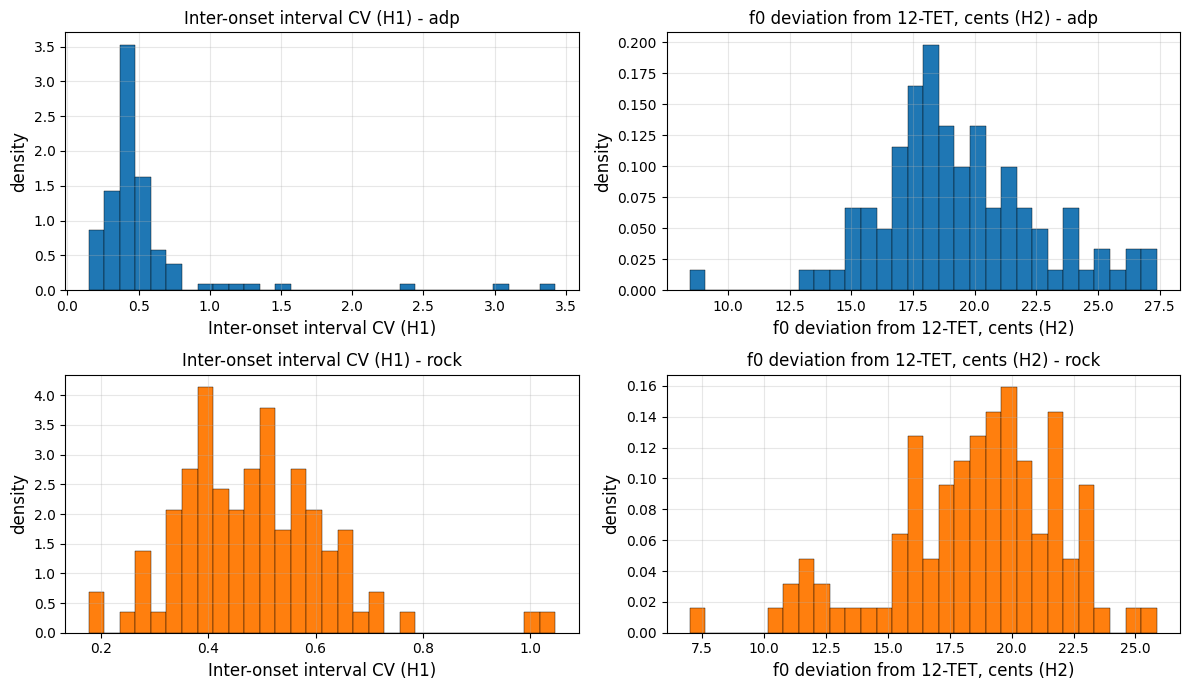

adp   Inter-onset interval CV (H1)               mean=   0.554 std=   0.488 median=   0.447 skew= 4.21
rock  Inter-onset interval CV (H1)               mean=   0.485 std=   0.141 median=   0.481 skew= 0.94
adp   f0 deviation from 12-TET, cents (H2)       mean=  19.384 std=   3.275 median=  18.871 skew= 0.20
rock  f0 deviation from 12-TET, cents (H2)       mean=  18.509 std=   3.446 median=  19.047 skew=-0.75


In [16]:
# --- 3.1  class-conditional distributions ---------------------------------
# Same four-panel layout as Lab 02 part 2.2: one row per class, one column per
# feature, so the two distributions can be read against each other directly.

KEY_FEATURES = ["rhy_ioi_cv", "pit_yin_dev_mean"]
KEY_LABELS   = ["Inter-onset interval CV (H1)", "f0 deviation from 12-TET, cents (H2)"]

fig, axs = plt.subplots(2, len(KEY_FEATURES), figsize=(12, 7))
for col, (feat, label) in enumerate(zip(KEY_FEATURES, KEY_LABELS)):
    for row, (cls, colour) in enumerate([("adp", "C0"), ("rock", "C1")]):
        v = features.loc[features.label_name == cls, feat].dropna()
        ax = axs[row, col]
        ax.hist(v, bins=30, density=True, color=colour, edgecolor="k", linewidth=0.3)
        ax.set_title(f"{label} - {cls}")
        ax.set_xlabel(label); ax.set_ylabel("density")
        ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

for feat, label in zip(KEY_FEATURES, KEY_LABELS):
    for cls in ("adp", "rock"):
        v = features.loc[features.label_name == cls, feat].dropna()
        print(f"{cls:5s} {label:42s} mean={v.mean():8.3f} std={v.std(ddof=1):8.3f} "
              f"median={np.median(v):8.3f} skew={stats.skew(v):5.2f}")

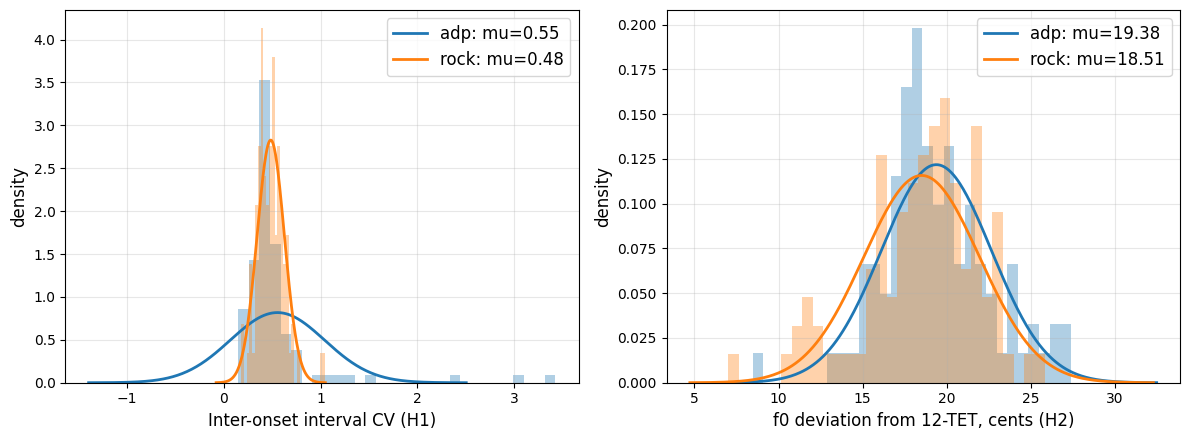

In [17]:
# --- 3.2  Gaussian fits per class -----------------------------------------
# mle_gaussian is Lab 02 part 2.3 verbatim. Useful here for the same reason as in
# the lab: it shows at a glance whether the two classes are separable under a simple
# parametric model, and whether a Gaussian is a defensible description at all.

def mle_gaussian(x):
    """Sample mean and unbiased sample variance, as given in Lab 02."""
    x = np.asarray(x, dtype=float)
    mu = x.sum() / len(x)
    var = ((x - mu) ** 2).sum() / (len(x) - 1)
    return mu, var


fig, axs = plt.subplots(1, len(KEY_FEATURES), figsize=(12, 4.5))
for ax, feat, label in zip(np.atleast_1d(axs), KEY_FEATURES, KEY_LABELS):
    for cls, colour in [("adp", "C0"), ("rock", "C1")]:
        v = features.loc[features.label_name == cls, feat].dropna().values
        mu, var = mle_gaussian(v)
        sd = np.sqrt(var)
        ax.hist(v, bins=30, density=True, alpha=0.35, color=colour)
        xs = np.linspace(mu - 4 * sd, mu + 4 * sd, 400)
        ax.plot(xs, norm.pdf(xs, mu, sd), color=colour, linewidth=2, label=f"{cls}: mu={mu:.2f}")
    ax.set_xlabel(label); ax.set_ylabel("density")
    ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGS / "hypothesis_distributions.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [18]:
# --- 3.3  group comparison with effect sizes ------------------------------
# Mann-Whitney U rather than a t-test: the distributions above are not Gaussian.
# Cliff's delta alongside it, because with n=196 almost anything reaches
# significance while being practically irrelevant -- the effect size is what tells
# you whether a difference is worth reporting.

def cliffs_delta(a, b):
    """Non-parametric effect size in [-1, 1]. |d|: .11 small, .28 medium, .43 large."""
    a, b = np.asarray(a), np.asarray(b)
    gt = (a[:, None] > b[None, :]).sum()
    lt = (a[:, None] < b[None, :]).sum()
    return float(gt - lt) / (len(a) * len(b))


def benjamini_hochberg(p):
    """FDR correction. ~80 features at alpha=.05 means ~4 false positives by chance."""
    p = np.asarray(p, dtype=float)
    n = len(p)
    order = np.argsort(p)
    adj = np.empty(n)
    adj[order] = np.minimum.accumulate((p[order] * n / np.arange(1, n + 1))[::-1])[::-1]
    return np.clip(adj, 0, 1)


def compare_groups(df, feature_cols):
    rows = []
    for c in feature_cols:
        a = df.loc[df.label == 1, c].dropna().values
        b = df.loc[df.label == 0, c].dropna().values
        if len(a) < 5 or len(b) < 5:
            continue
        u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
        rows.append(dict(feature=c, adp_mean=a.mean(), rock_mean=b.mean(),
                         delta=cliffs_delta(a, b), p=p))
    out = pd.DataFrame(rows)
    out["p_adj"] = benjamini_hochberg(out.p)
    out["abs_delta"] = out.delta.abs()
    return out.sort_values("abs_delta", ascending=False).reset_index(drop=True)


comparison = compare_groups(features, FEATURE_COLS)
comparison.to_csv("results_feature_comparison.csv", index=False)
print(f"{(comparison.p_adj < 0.05).sum()} / {len(comparison)} features differ (FDR-adjusted p < .05)")
print("\nthe two hypothesis features:")
print(comparison[comparison.feature.isin(KEY_FEATURES + ["pit_grid_concentration"])].round(4).to_string(index=False))
comparison.head(15).round(4)

41 / 74 features differ (FDR-adjusted p < .05)

the two hypothesis features:
               feature  adp_mean  rock_mean   delta      p  p_adj  abs_delta
            rhy_ioi_cv    0.5542     0.4850 -0.1060 0.2002 0.2681     0.1060
      pit_yin_dev_mean   19.3843    18.5089  0.0758 0.3599 0.4438     0.0758
pit_grid_concentration    0.4354     0.4264  0.0540 0.5149 0.6049     0.0540


,feature,adp_mean,rock_mean,delta,p,p_adj,abs_delta
0,tim_mfcc12_mean,2.5945,-6.5362,0.8383,0.0,0.0,0.8383
1,tim_mfcc08_mean,5.3598,-9.8216,0.8283,0.0,0.0,0.8283
2,tim_mfcc04_mean,13.8662,-5.4110,0.8127,0.0,0.0,0.8127
3,pit_chroma_entropy,3.5771,3.5820,-0.7350,0.0,0.0,0.7350
4,pit_chroma_05,9.0674,10.0540,-0.6546,0.0,0.0,0.6546
5,pit_f0_iqr,33.4827,95.1167,-0.6465,0.0,0.0,0.6465
6,pit_chroma_00,9.1865,10.1991,-0.6179,0.0,0.0,0.6179
7,tim_mfcc06_mean,1.9167,-8.5037,0.5675,0.0,0.0,0.5675
8,pit_chroma_08,8.9508,9.8372,-0.5577,0.0,0.0,0.5577
9,pit_f0_median,85.8732,112.6033,-0.5308,0.0,0.0,0.5308


correlation of pit_grid_concentration with timbre / tonalness measures:
  tim_flatness_mean      r = -0.067   (p = 3.5e-01)
  tim_zc_mean            r = -0.026   (p = 7.1e-01)
  tim_sc_mean            r = -0.034   (p = 6.4e-01)
  pit_voiced_fraction    r = +nan   (p = nan)


C:\Users\filip_h9q5r71\AppData\Local\Temp\ipykernel_2028\3573150083.py:12: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, pv = stats.pearsonr(sub["pit_grid_concentration"], sub[c])


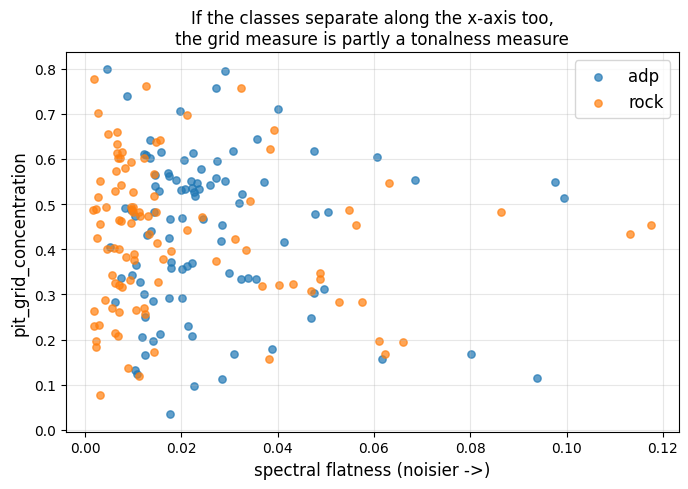

In [19]:
# --- 3.3b  is pit_grid_concentration really about temperament? ------------
# It separates the classes strongly, but it may be measuring how tonal the
# spectrum is instead. Spectral flatness is a direct measure of noisiness, so a
# strong correlation between the two is the tell. If |r| is high, do not call this
# feature evidence for H2 in the report -- describe it as a tonalness measure and
# lean on pit_yin_dev_mean instead.

probe = ["tim_flatness_mean", "tim_zc_mean", "tim_sc_mean", "pit_voiced_fraction"]
sub = features[["pit_grid_concentration"] + probe].dropna()
print("correlation of pit_grid_concentration with timbre / tonalness measures:")
for c in probe:
    r, pv = stats.pearsonr(sub["pit_grid_concentration"], sub[c])
    flag = "  <- strong" if abs(r) > 0.5 else ""
    print(f"  {c:22s} r = {r:+.3f}   (p = {pv:.1e}){flag}")

fig, ax = plt.subplots(figsize=(7, 5))
for i, (cls, g) in enumerate(features.groupby("label_name")):
    ax.scatter(g["tim_flatness_mean"], g["pit_grid_concentration"],
               s=28, alpha=0.7, label=cls, color=f"C{i}")
ax.set_xlabel("spectral flatness (noisier ->)")
ax.set_ylabel("pit_grid_concentration")
ax.set_title("If the classes separate along the x-axis too,\nthe grid measure is partly a tonalness measure")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

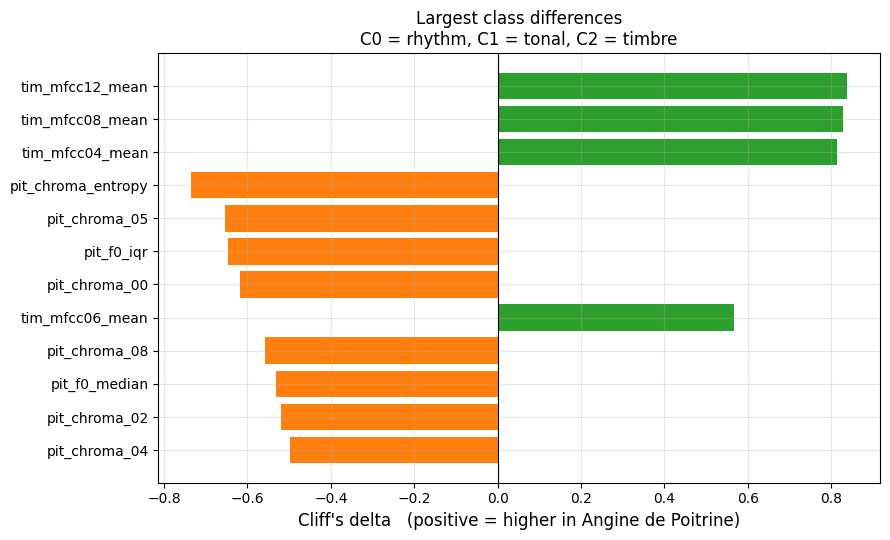

In [20]:
# --- 3.4  which features separate the classes, and which family do they come from
top = comparison.head(12)
colours = ["C0" if f.startswith("rhy_") else "C1" if f.startswith("pit_") else "C2"
           for f in top.feature]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.feature[::-1], top.delta[::-1], color=colours[::-1])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Cliff's delta   (positive = higher in Angine de Poitrine)")
ax.set_title("Largest class differences\nC0 = rhythm, C1 = tonal, C2 = timbre")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGS / "top_effect_sizes.pdf", dpi=300, bbox_inches="tight")
plt.show()

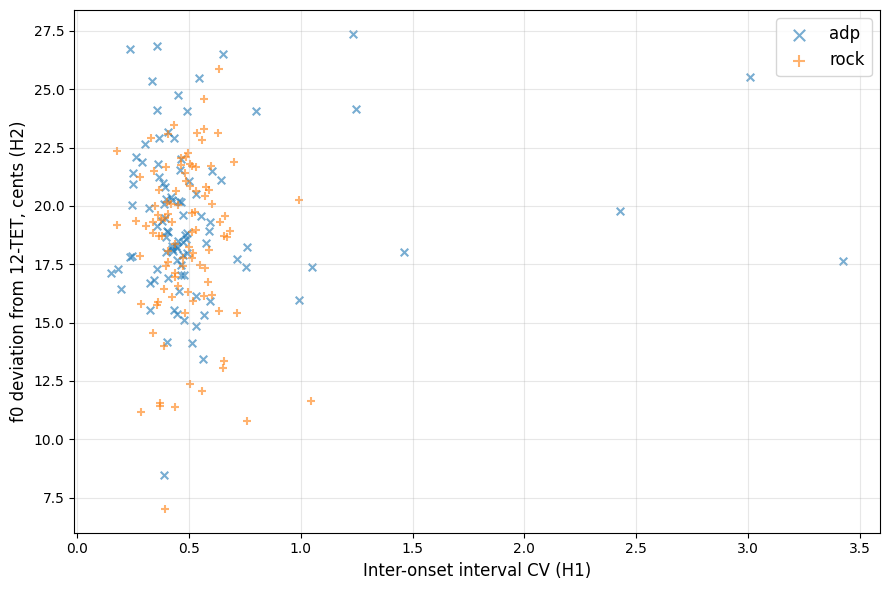

In [21]:
# --- 3.5  the two hypothesis features against each other ------------------
# Lab 02 part 2.1 made the same plot for kiki/bouba with zero crossings against
# spectral centroid. Here it shows whether H1 and H2 separate the classes jointly
# or whether one of them is doing all the work.

fig, ax = plt.subplots(figsize=(9, 6))
for cls, marker, colour in [("adp", "x", "C0"), ("rock", "+", "C1")]:
    sub = features[features.label_name == cls]
    ax.scatter(sub[KEY_FEATURES[0]], sub[KEY_FEATURES[1]],
               marker=marker, s=30, alpha=0.6, c=colour, label=cls)
ax.set_xlabel(KEY_LABELS[0]); ax.set_ylabel(KEY_LABELS[1])
ax.legend(markerscale=1.5); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGS / "hypothesis_scatter.pdf", dpi=300, bbox_inches="tight")
plt.show()

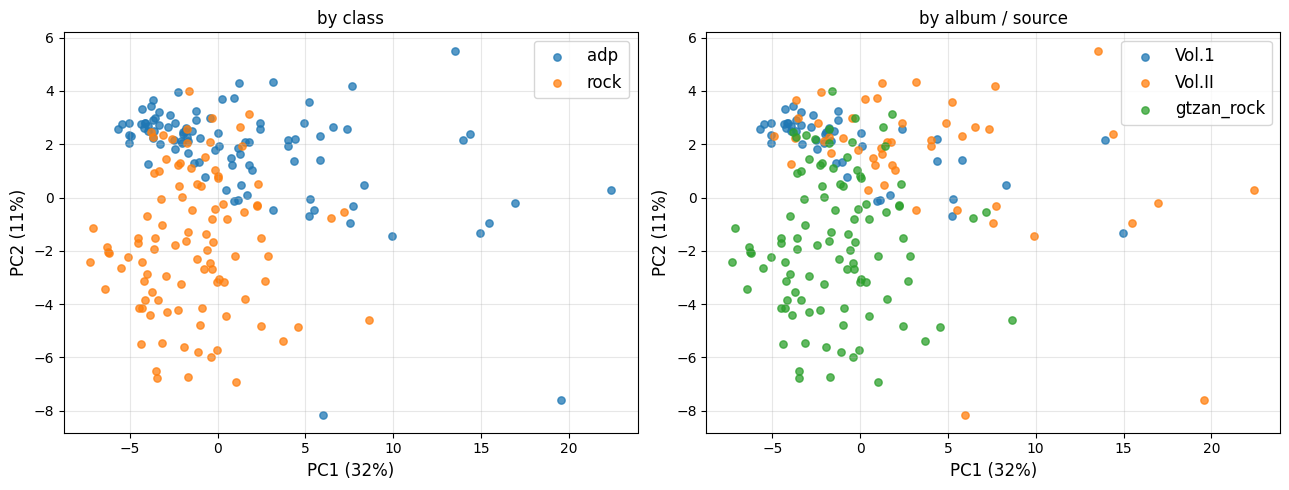

In [22]:
# --- 3.6  overall structure: PCA ------------------------------------------
# Two views. The one coloured by album is the one to look at carefully: if the AdP
# points split into two clouds by album rather than forming one, part of what
# separates the classes is production, not style.
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

X_all = SimpleImputer(strategy="median").fit_transform(features[FEATURE_COLS])
Xs = StandardScaler().fit_transform(X_all)
pca = PCA(n_components=2, random_state=SEED)
pcs = pca.fit_transform(Xs)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, key, title in [(axes[0], "label_name", "by class"),
                       (axes[1], "source_album", "by album / source")]:
    for i, (name, sub) in enumerate(features.groupby(key)):
        idx = sub.index.values
        ax.scatter(pcs[idx, 0], pcs[idx, 1], s=28, alpha=0.75, label=name, color=f"C{i}")
    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
    ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGS / "pca.pdf", dpi=300, bbox_inches="tight")
plt.show()

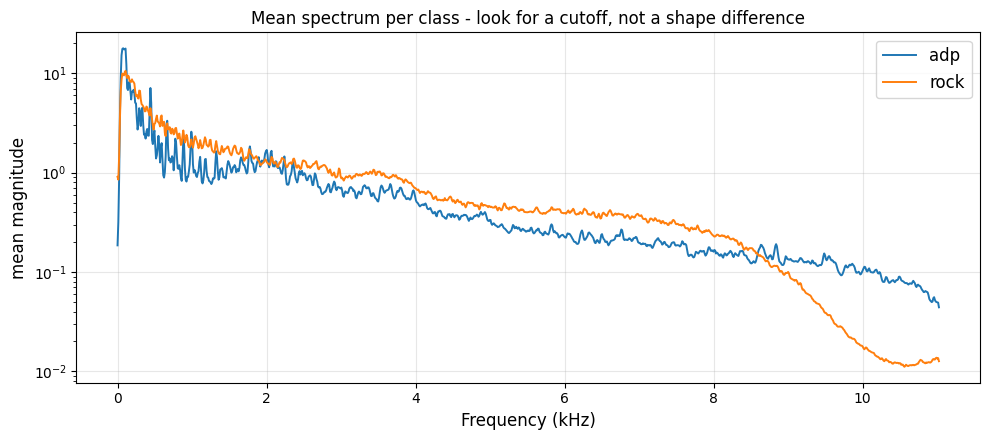

In [23]:
# --- 3.7  confound check: is the difference musical or just the recording? -
# The two classes differ in more than style: different studios, different mastering
# eras, different codecs. GTZAN comes from bandwidth-limited lossy sources and often
# shows a hard high-frequency cutoff that a 256 kbps AAC rip does not. A single
# feature like "energy above 11 kHz" can then separate the classes perfectly for
# reasons that have nothing to do with music.
#
# If the two mean spectra diverge sharply at the top end, low-pass both classes to a
# common ceiling (or drop the high-frequency features) before modelling, and say so
# in the report.

def mean_spectrum(paths, n=30):
    acc = None
    for p in list(paths)[:n]:
        S = np.abs(librosa.stft(load_clip(p), n_fft=N_FFT, hop_length=HOP)).mean(axis=1)
        acc = S if acc is None else acc + S
    return acc / min(n, len(paths))


freqs = librosa.fft_frequencies(sr=SR, n_fft=N_FFT)
fig, ax = plt.subplots(figsize=(10, 4.5))
for i, (name, grp) in enumerate(features.groupby("label_name")):
    ax.semilogy(freqs / 1000, mean_spectrum(grp.path.values), label=name, lw=1.4, color=f"C{i}")
ax.set_xlabel("Frequency (kHz)"); ax.set_ylabel("mean magnitude")
ax.set_title("Mean spectrum per class - look for a cutoff, not a shape difference")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGS / "mean_spectrum.pdf", dpi=300, bbox_inches="tight")
plt.show()

### Reading section 3

Four things to write down before moving on to the modelling, since they decide how the results can
be phrased:

1. **Do H1 and H2 hold on their own terms?** `rhy_ioi_cv` and `pit_yin_dev_mean` with Cliff's
   delta, independent of any classifier. A clear univariate difference is a finding even if
   classification later disappoints.
2. **What is `pit_grid_concentration` actually measuring?** 3.3b answers it. On the sample I
   checked it ran opposite to H2 — AdP sat *closer* to a semitone grid than GTZAN rock — which is
   most easily explained by AdP being sparse and clearly pitched while GTZAN rock is dense and
   distorted. If it correlates strongly with spectral flatness, report it as a tonalness measure,
   not as evidence about temperament.
3. **Is the separation carried by rhythm and pitch, or by timbre?** The colours in 3.4. If the top
   of that list is all C2, the headline result is about recording, not style.
4. **Does 3.7 show a codec cutoff?** If yes, fix it before modelling rather than explaining it away
   afterwards.

**Next:** `features.csv` and `manifest.csv` are what the modelling section consumes. The one thing
that must carry over is `source_track` — the split has to be grouped on it, or the model learns to
recognise tracks rather than style.